# Privacy Group Stance over Time

| Item | Description |
|---|---|
| Goal | Plot the share of supportive legislator statements for the Privacy and digital consumer protection group by Congress in two panels: consumer data privacy legislation alone (Panel A), and the group's other four topics pooled (Panel B), with one shared legend. |
| Input | The approved `topic_groups.csv`; saved `track2_assigned.parquet` and `hearings_sst.parquet` under `/project2/mmiric_1435/acroh/llm_method/data`. |
| Output | Two single-panel figures (Panels A and B by Congress) and one combined image with both panels side by side above the shared legend, in PNG, SVG, and PDF, plus Congress-level and presidential-term count CSVs with a panel column, in `output/T2.4.2/` beside this notebook. |
| Unit | An original extracted stance record, that is, one legislator statement of a position on a topic. A speech turn may contain multiple statements. This retains the reference figure's measure, unlike the distinct-turn bars in T2.4.1. |
| Sample | All records assigned to the approved privacy group's topics in House Science and Senate Commerce hearings held in 1999–2025. |
| Group definition | Topic groups manually cluster topics from topic extraction. The mapping file determines group membership. Panel A is the topic labeled `consumer data privacy legislation`; Panel B pools the group's other four topics. |
| Stances | Support means endorsement, advocacy, or urging adoption, funding, or expansion of a topic. Concern means worry, criticism, objection, or urging restriction, delay, or scrutiny. Definitions follow the Track 2 extraction prompt reproduced in Appendix A.2 of `Proposal_for_Org_Sci_101126_AR.md`. |
| Variables | • `support_records` and `concern_records`: $S_{gt}$ and $C_{gt}$, numbers of support and concern statements in panel $g$ and Congress $t$, pooled across all hearings held during that Congress.<br>• `n_records`: $N_{gt}=S_{gt}+C_{gt}$, total stance statements.<br>• `n_hearings`, `n_turns`, and `n_legislators`: distinct hearings, speech turns, and legislators represented in each period.<br>• `support_share`: $p_{gt}=S_{gt}/(S_{gt}+C_{gt})$, the share of statements that are supportive; missing when a period has no statements.<br>• `se_clustered`: hearing-clustered standard error of $p_{gt}$, $\sqrt{\tfrac{H}{H-1}\sum_{h}(S_{ght}-p_{gt}N_{ght})^2}\,/\,N_{gt}$, where $S_{ght}$ and $N_{ght}$ are the support and total statements of hearing $h$ and $H$ is the number of hearings in period $t$; missing when $H<2$.<br>• `ci_lower` and `ci_upper`: $p_{gt} \pm 1.96\,\mathrm{SE}$, clipped to $[0,1]$.<br>• `congress`: the Congress in which the hearing was held, $106 + \lfloor (t - 1999)/2 \rfloor$ for hearing year $t$, so the 106th Congress is 1999–2000 and the 119th is 2025; checked against the Congress number in the GovInfo package identifier. |
| Presidential-term shares | Pool all statements in each calendar-year block: Clinton 1999–2000, Bush 2001–2008, Obama 2009–2016, Trump I 2017–2020, Biden 2021–2024, and Trump II 2025. These are sample windows, not exact inauguration dates. |
| Interpretation | The unit is the statement. The error bars treat hearings as the independent units (standard errors clustered by hearing), so repeated statements within one hearing do not inflate precision. No break-year search, minimum-cell threshold, or screening test is applied. |

Follow the shared figure guide: one panel per image, a fixed 9-by-6-inch canvas, the prescribed colors and serif font, and captions outside the exported image. The Y-titles are in title case and name the topic in full, and Step 18 also exports one image with both panels side by side above the shared legend for the document. This notebook is independent of the raw-turn export notebook.


## Step 1. Import packages

Read saved data and display the exported figures.


In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import Image, Markdown, display


## Step 2. Define file locations

Read the source files in place and save outputs in `output/T2.4.2/` beside this notebook.

In [2]:
PROJECT_FOLDER = Path("/project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis")
SOURCE_DATA_FOLDER = Path("/project2/mmiric_1435/acroh/llm_method/data")
NOTEBOOK_SUBFOLDER = Path(
    "T2 - Topic Extraction and Stance Analysis/T2.4 - Running Example Selection"
)
GROUPS_FILE = PROJECT_FOLDER / NOTEBOOK_SUBFOLDER / "topic_groups.csv"
RECORDS_FILE = SOURCE_DATA_FOLDER / "interim/topics/taxonomy/track2_assigned.parquet"
HEARINGS_FILE = SOURCE_DATA_FOLDER / "interim/repo_data/raw/02_hearings/hearings_sst.parquet"
OUTPUT_FOLDER = PROJECT_FOLDER / NOTEBOOK_SUBFOLDER / "output" / "T2.4.2"

TARGET_GROUP = "Privacy and digital consumer protection"
PANEL_A_TOPIC_LABEL = "consumer data privacy legislation"  # the one topic drawn alone in Panel A
PANEL_NAMES = {
    "A": "Consumer data privacy legislation",
    "B": "Other four privacy and digital consumer protection topics pooled",
}
Y_TITLES = {  # title case; three lines so the longest line fits the axis height
    "A": (
        "Share of Legislator Statements in Each Congress\n"
        "With a Supportive Stance (Versus Concern)\n"
        "on the “Consumer Data Privacy Legislation”"
    ),
    "B": (
        "Share of Legislator Statements in Each Congress\n"
        "With a Supportive Stance (Versus Concern)\n"
        "on the Other Four “Privacy and Digital Consumer Protection” Topics"
    ),
}
YEAR_MIN = 1999
YEAR_MAX = 2025
FIRST_CONGRESS = 106  # the Congress that convened in January of YEAR_MIN
CONFIDENCE_Z = 1.96  # 95 percent interval half-width in standard errors
TURN_KEYS = ["packageId", "turn_idx"]
ADMINISTRATION_WINDOWS = [
    ("Clinton", 1999, 2000),
    ("Bush", 2001, 2008),
    ("Obama", 2009, 2016),
    ("Trump I", 2017, 2020),
    ("Biden", 2021, 2024),
    ("Trump II", 2025, 2025),
]
OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)
print(f"Outputs: {OUTPUT_FOLDER}")


Outputs: /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T2 - Topic Extraction and Stance Analysis/T2.4 - Running Example Selection/output/T2.4.2


## Step 3. Apply the figure style

Use the shared canvas, font, colors, and margins, with a slightly thicker solid reference line at 0.5, where support and concern statements are equally common. Use DejaVu Serif for bold presidential-term labels because the installed Times New Roman font has no bold face. Presidential terms are alternating grey bands, not vertical background grid lines. The combined figure in Step 18 draws the shared legend at a slightly smaller font so that both entries fit in one row.


In [3]:
RED = "#B31942"
BLUE = "#0A3161"
MIDNIGHT_BLUE = "#004953"
GREY = "#A6A6A8"
BLACK = "#101820"
FIGURE_WIDTH = 9
FIGURE_HEIGHT = 6
MARGIN_INCHES = 0.5 / 2.54
EQUAL_SHARE = 0.5  # support and concern statements equally common
REFERENCE_LINE_WIDTH = 0.6
TERM_BAND_ALPHA = 0.3
EXPORT_DPI = 300
BOLD_TEXT = {"fontweight": "bold", "fontfamily": "DejaVu Serif"}
LEGEND_FONT_SIZE = 10  # the dashed-line entry is 8.3 inches wide at 11 points
COMBINED_FIGURE_WIDTH = 2 * FIGURE_WIDTH  # Panels A and B side by side
COMBINED_FIGURE_HEIGHT = FIGURE_HEIGHT + 0.5  # room for the one-row shared legend below the X-titles

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman", "Times", "Liberation Serif", "DejaVu Serif"]
plt.rcParams["font.size"] = 11
plt.rcParams["figure.figsize"] = (FIGURE_WIDTH, FIGURE_HEIGHT)
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["axes.unicode_minus"] = True
plt.rcParams["axes.grid"] = True
plt.rcParams["axes.grid.axis"] = "y"
plt.rcParams["axes.axisbelow"] = True
plt.rcParams["grid.color"] = GREY
plt.rcParams["grid.linewidth"] = 0.5
plt.rcParams["text.color"] = BLACK
plt.rcParams["axes.labelcolor"] = BLACK
plt.rcParams["axes.edgecolor"] = BLACK
plt.rcParams["xtick.color"] = BLACK
plt.rcParams["ytick.color"] = BLACK


## Step 4. Select the privacy group's topics

Use all topics in the approved group. Check that topic identifiers map uniquely to groups.

In [4]:
topic_groups = pd.read_csv(GROUPS_FILE)
assert topic_groups["topic_id"].is_unique
assert topic_groups[["group", "topic_id", "label"]].notna().all().all()
selected_topics = topic_groups.loc[topic_groups["group"].eq(TARGET_GROUP)].copy()
assert not selected_topics.empty
print(f"Topic mapping rows: {len(topic_groups):,}; selected topics: {len(selected_topics):,}")
display(selected_topics)

Topic mapping rows: 111; selected topics: 5


,group,label,topic_id
46,Privacy and digital consumer protection,Consumer privacy and anti-spam legislation,65
47,Privacy and digital consumer protection,Digital identity verification and protection,67
48,Privacy and digital consumer protection,consumer data privacy legislation,68
49,Privacy and digital consumer protection,Children's online privacy and safety legislation,92
50,Privacy and digital consumer protection,Online advertising and consumer choice policies,93


## Step 5. Load the group's stance records

Keep original extracted records rather than collapsing repeated positions within a speech turn. Each record must have one support or concern label.

In [5]:
privacy_records = pd.read_parquet(
    RECORDS_FILE,
    columns=TURN_KEYS + ["bioGuideId", "record_idx", "topic_id", "stance"],
    filters=[("topic_id", "in", selected_topics["topic_id"].tolist())],
)
assert privacy_records[TURN_KEYS + ["bioGuideId", "record_idx"]].notna().all().all()
assert privacy_records["stance"].isin(["support", "concern"]).all()
assert not privacy_records.duplicated(TURN_KEYS + ["record_idx"]).any()
assert privacy_records["topic_id"].isin(selected_topics["topic_id"]).all()
print(f"Privacy-group stance records loaded: {len(privacy_records):,}")
display(privacy_records.head(3))

Privacy-group stance records loaded: 1,654


,packageId,turn_idx,bioGuideId,record_idx,topic_id,stance
0,CHRG-106shrg69984,4,K000148,1,68,support
1,CHRG-106shrg69984,4,K000148,4,65,concern
2,CHRG-106shrg69984,4,K000148,5,65,support


## Step 6. Load hearing dates

Use hearing held dates, not the source record's year field, to match the existing grouped figure.

In [6]:
hearings = pd.read_parquet(HEARINGS_FILE, columns=["packageId", "heldDate_first"])
assert hearings["packageId"].is_unique
print(f"Hearing metadata rows: {len(hearings):,}")
display(hearings.head(3))

Hearing metadata rows: 2,352


,packageId,heldDate_first
0,CHRG-104hhrg37345,1996-08-01
1,CHRG-105hhrg38882,1997-02-12
2,CHRG-106hhrg58508,1999-07-13


## Step 7. Attach the hearing year

A many-to-one join attaches one held date per hearing without multiplying records.

In [7]:
privacy_records = privacy_records.merge(
    hearings, on="packageId", how="left", validate="many_to_one"
)
assert privacy_records["heldDate_first"].notna().all()
privacy_records["hearing_year"] = pd.to_datetime(privacy_records["heldDate_first"]).dt.year
print(f"Dated stance records: {len(privacy_records):,}")
display(privacy_records[TURN_KEYS + ["hearing_year", "stance"]].head(3))

Dated stance records: 1,654


,packageId,turn_idx,hearing_year,stance
0,CHRG-106shrg69984,4,1999,support
1,CHRG-106shrg69984,4,1999,concern
2,CHRG-106shrg69984,4,1999,support


## Step 8. Apply the sample window

Retain all privacy-group records in hearings held during 1999–2025, without screening thresholds.

In [8]:
records_before_filter = len(privacy_records)
privacy_records = privacy_records.loc[
    privacy_records["hearing_year"].between(YEAR_MIN, YEAR_MAX)
].copy()
assert not privacy_records.empty
privacy_records = privacy_records.sort_values(
    ["hearing_year", "packageId", "turn_idx", "record_idx"]
)
print(f"Records in {YEAR_MIN}–{YEAR_MAX}: {len(privacy_records):,}")
print(f"Records outside the window: {records_before_filter - len(privacy_records):,}")
print(f"Hearings: {privacy_records['packageId'].nunique():,}")
print(f"Speech turns: {len(privacy_records.drop_duplicates(TURN_KEYS)):,}")
print(f"Legislators: {privacy_records['bioGuideId'].nunique():,}")
display(privacy_records.head(3))

Records in 1999–2025: 1,654
Records outside the window: 0
Hearings: 551
Speech turns: 1,086
Legislators: 152


,packageId,turn_idx,bioGuideId,record_idx,topic_id,stance,heldDate_first,hearing_year
325,CHRG-106shrg69592,17,0000000,1,93,concern,1999-05-26,1999
701,CHRG-106shrg69984,1,B001126,1,65,support,1999-06-10,1999
702,CHRG-106shrg69984,1,B001126,3,65,support,1999-06-10,1999


## Step 9. Assign each topic to a panel

Loop over the group's five topics. The topic labeled consumer data privacy legislation forms Panel A on its own; the other four topics are pooled in Panel B.


In [9]:
panel_by_topic = {}
for topic in selected_topics.itertuples(index=False):
    panel_by_topic[topic.topic_id] = "A" if topic.label == PANEL_A_TOPIC_LABEL else "B"
selected_topics["panel"] = selected_topics["topic_id"].map(panel_by_topic)
assert selected_topics["panel"].eq("A").sum() == 1
assert selected_topics["panel"].eq("B").sum() == len(selected_topics) - 1
privacy_records["panel"] = privacy_records["topic_id"].map(panel_by_topic)
assert privacy_records["panel"].notna().all()
print(f"Records by panel: {privacy_records['panel'].value_counts().sort_index().to_dict()}")
display(selected_topics)


Records by panel: {'A': 374, 'B': 1280}


,group,label,topic_id,panel
46,Privacy and digital consumer protection,Consumer privacy and anti-spam legislation,65,B
47,Privacy and digital consumer protection,Digital identity verification and protection,67,B
48,Privacy and digital consumer protection,consumer data privacy legislation,68,A
49,Privacy and digital consumer protection,Children's online privacy and safety legislation,92,B
50,Privacy and digital consumer protection,Online advertising and consumer choice policies,93,B


## Step 10. Assign each hearing and each presidential term to a Congress

A Congress covers two calendar years beginning in an odd year, so the 106th Congress is 1999–2000 and the 119th is 2025. Check the rule against the Congress number recorded in each GovInfo package identifier. The presidential-term blocks align with Congress boundaries, so each term maps to a first and last Congress.


In [10]:
assert YEAR_MIN % 2 == 1  # a Congress begins in an odd year
CONGRESS_MIN = FIRST_CONGRESS
CONGRESS_MAX = FIRST_CONGRESS + (YEAR_MAX - YEAR_MIN) // 2
privacy_records["congress"] = FIRST_CONGRESS + (privacy_records["hearing_year"] - YEAR_MIN) // 2
congress_in_id = privacy_records["packageId"].str.extract(r"^CHRG-(\d+)[hs]hrg", expand=False).astype("Int64")
assert (congress_in_id.dropna() == privacy_records.loc[congress_in_id.notna(), "congress"]).all()

TERM_CONGRESSES = {}
for administration, first_year, last_year in ADMINISTRATION_WINDOWS:
    TERM_CONGRESSES[administration] = (
        FIRST_CONGRESS + (first_year - YEAR_MIN) // 2,
        FIRST_CONGRESS + (last_year - YEAR_MIN) // 2,
    )
hearings_by_congress = privacy_records.drop_duplicates("packageId").groupby("congress").size()
print(f"Congresses {CONGRESS_MIN}–{CONGRESS_MAX}; identifiers checked for {congress_in_id.notna().sum():,} of {len(privacy_records):,} records")
print(f"Term to Congress mapping: {TERM_CONGRESSES}")
print("Hearings per Congress:")
print(hearings_by_congress.to_string())


Congresses 106–119; identifiers checked for 1,653 of 1,654 records
Term to Congress mapping: {'Clinton': (106, 106), 'Bush': (107, 110), 'Obama': (111, 114), 'Trump I': (115, 116), 'Biden': (117, 118), 'Trump II': (119, 119)}
Hearings per Congress:
congress
106    22
107    46
108    31
109    41
110    44
111    43
112    35
113    46
114    43
115    58
116    48
117    49
118    23
119    22


## Step 11. Count statements by panel and Congress

For each panel, pool all hearings held during one Congress and count support and concern statements. Include every Congress in the window. The support share is support statements ÷ (support + concern statements); leave it missing if a Congress had no statements, which Step 12 checks does not happen.


In [11]:
count_columns = ["n_hearings", "n_turns", "n_legislators"]
congress_rows = []
for panel in PANEL_NAMES:
    panel_records = privacy_records.loc[privacy_records["panel"].eq(panel)]
    panel_counts = pd.crosstab(panel_records["congress"], panel_records["stance"])
    panel_counts = panel_counts.reindex(
        index=range(CONGRESS_MIN, CONGRESS_MAX + 1), columns=["support", "concern"], fill_value=0
    )
    panel_counts = panel_counts.rename(
        columns={"support": "support_records", "concern": "concern_records"}
    )
    panel_counts.columns.name = None
    panel_counts["n_records"] = panel_counts["support_records"] + panel_counts["concern_records"]
    panel_counts["n_hearings"] = panel_records.groupby("congress")["packageId"].nunique()
    panel_counts["n_turns"] = panel_records.drop_duplicates(TURN_KEYS).groupby("congress").size()
    panel_counts["n_legislators"] = panel_records.groupby("congress")["bioGuideId"].nunique()
    panel_counts[count_columns] = panel_counts[count_columns].fillna(0).astype(int)
    panel_counts["support_share"] = panel_counts["support_records"] / panel_counts["n_records"].where(
        panel_counts["n_records"].gt(0)
    )
    panel_counts.index.name = "congress"
    panel_counts = panel_counts.reset_index()
    panel_counts.insert(0, "panel", panel)
    congress_rows.append(panel_counts)
congress_counts = pd.concat(congress_rows, ignore_index=True)
assert congress_counts["n_records"].sum() == len(privacy_records)
print(f"Congress rows: {len(congress_counts):,}; total records: {congress_counts['n_records'].sum():,}")
print(f"Fewest hearings in one Congress: {congress_counts.groupby('panel')['n_hearings'].min().to_dict()}")
display(congress_counts.head(3))


Congress rows: 28; total records: 1,654
Fewest hearings in one Congress: {'A': 3, 'B': 18}


,panel,congress,support_records,concern_records,n_records,n_hearings,n_turns,n_legislators,support_share
0,A,106,22,20,42,6,20,8,0.523810
1,A,107,15,13,28,4,13,8,0.535714
2,A,108,5,7,12,6,10,5,0.416667


## Step 12. Compute hearing-clustered intervals for each Congress share

The point stays the pooled share with the statement as the unit. For its uncertainty, treat each hearing, not each statement, as the independent unit: the standard error is the hearing-clustered standard error of the pooled share, and the 95 percent interval is the share plus or minus 1.96 standard errors, clipped to 0 and 1. A Congress with one hearing would get no interval; check that every Congress has at least two in both panels.


In [12]:
privacy_records["is_support"] = privacy_records["stance"].eq("support").astype(int)
congress_counts["se_clustered"] = float("nan")
for row_index, counts in congress_counts.iterrows():
    if counts["n_hearings"] < 2:
        continue  # a clustered standard error needs at least two hearings
    period_records = privacy_records.loc[
        privacy_records["panel"].eq(counts["panel"])
        & privacy_records["congress"].eq(counts["congress"])
    ]
    hearing_counts = period_records.groupby("packageId")["is_support"].agg(["sum", "size"])
    residuals = hearing_counts["sum"] - counts["support_share"] * hearing_counts["size"]
    hearing_count = len(hearing_counts)
    congress_counts.loc[row_index, "se_clustered"] = (
        (residuals.pow(2).sum() * hearing_count / (hearing_count - 1)) ** 0.5 / counts["n_records"]
    )
congress_counts["ci_lower"] = (
    congress_counts["support_share"] - CONFIDENCE_Z * congress_counts["se_clustered"]
).clip(lower=0)
congress_counts["ci_upper"] = (
    congress_counts["support_share"] + CONFIDENCE_Z * congress_counts["se_clustered"]
).clip(upper=1)
assert congress_counts["support_share"].notna().all()
assert congress_counts["se_clustered"].notna().all()
print(f"Intervals computed for all {len(congress_counts):,} panel-by-Congress rows")
display(congress_counts[["panel", "congress", "n_records", "n_hearings", "support_share", "se_clustered", "ci_lower", "ci_upper"]].head(3))


Intervals computed for all 28 panel-by-Congress rows


,panel,congress,n_records,n_hearings,support_share,se_clustered,ci_lower,ci_upper
0,A,106,42,6,0.523810,0.057294,0.411514,0.636105
1,A,107,28,4,0.535714,0.048133,0.441374,0.630054
2,A,108,12,6,0.416667,0.099187,0.222261,0.611072


## Step 13. Pool statements within presidential terms

For each panel, compute the term share from pooled statements, not an unweighted average of Congress-level shares. Calendar-year blocks are clipped to the sample period.


In [13]:
administration_rows = []
for panel in PANEL_NAMES:
    for administration, first_year, last_year in ADMINISTRATION_WINDOWS:
        period_records = privacy_records.loc[
            privacy_records["panel"].eq(panel)
            & privacy_records["hearing_year"].between(first_year, last_year)
        ]
        support_records = int(period_records["stance"].eq("support").sum())
        concern_records = int(period_records["stance"].eq("concern").sum())
        n_records = support_records + concern_records
        administration_rows.append({
            "panel": panel,
            "administration": administration,
            "first_year": first_year,
            "last_year": last_year,
            "support_records": support_records,
            "concern_records": concern_records,
            "n_records": n_records,
            "n_hearings": period_records["packageId"].nunique(),
            "n_turns": len(period_records.drop_duplicates(TURN_KEYS)),
            "n_legislators": period_records["bioGuideId"].nunique(),
            "support_share": support_records / n_records if n_records else float("nan"),
        })
administration_counts = pd.DataFrame(administration_rows)
print(f"Administration rows: {len(administration_counts):,}")
display(administration_counts)


Administration rows: 12


,panel,administration,first_year,last_year,support_records,concern_records,n_records,n_hearings,n_turns,n_legislators,support_share
0,A,Clinton,1999,2000,22,20,42,6,20,8,0.523810
1,A,Bush,2001,2008,27,30,57,18,34,14,0.473684
2,A,Obama,2009,2016,42,44,86,37,60,29,0.488372
3,A,Trump I,2017,2020,70,31,101,28,69,23,0.693069
4,A,Biden,2021,2024,57,25,82,26,55,22,0.695122
5,A,Trump II,2025,2025,3,3,6,4,5,5,0.500000
6,B,Clinton,1999,2000,24,62,86,21,51,16,0.279070
7,B,Bush,2001,2008,132,217,349,158,257,49,0.378223
8,B,Obama,2009,2016,97,188,285,150,223,65,0.340351
9,B,Trump I,2017,2020,80,170,250,99,176,52,0.320000


## Step 14. Check sample coverage

Ensure the Congress-level and presidential-term summaries retain every original record and distinct speech turn within each panel. A speech turn with statements on topics in both panels counts once in each panel. Construct concise sample information once for the figure notes.


In [14]:
panel_descriptions = {}
for panel in PANEL_NAMES:
    panel_records = privacy_records.loc[privacy_records["panel"].eq(panel)]
    panel_turns = panel_records.drop_duplicates(TURN_KEYS)
    panel_congress = congress_counts.loc[congress_counts["panel"].eq(panel)]
    panel_administration = administration_counts.loc[administration_counts["panel"].eq(panel)]
    assert panel_congress["n_records"].sum() == len(panel_records)
    assert panel_administration["n_records"].sum() == len(panel_records)
    assert panel_congress["n_turns"].sum() == len(panel_turns)
    assert panel_administration["n_turns"].sum() == len(panel_turns)
    assert panel_congress["n_hearings"].sum() == panel_records["packageId"].nunique()
    for stance in ["support", "concern"]:
        expected_records = panel_records["stance"].eq(stance).sum()
        assert panel_congress[f"{stance}_records"].sum() == expected_records
        assert panel_administration[f"{stance}_records"].sum() == expected_records
    panel_descriptions[panel] = (
        f"{panel_records['packageId'].nunique():,} hearings, "
        f"{len(panel_turns):,} legislator speech turns, and {len(panel_records):,} statements"
    )
assert congress_counts["n_records"].sum() == len(privacy_records)
assert set(privacy_records["topic_id"]) == set(selected_topics["topic_id"])

panel_b_topics = "; ".join(selected_topics.loc[selected_topics["panel"].eq("B"), "label"])
sample_description = (
    f"House Science and Senate Commerce hearings, {YEAR_MIN}–{YEAR_MAX}. "
    f"Panel A covers the topic {PANEL_A_TOPIC_LABEL}: {panel_descriptions['A']}. "
    f"Panel B pools the group's other {len(selected_topics) - 1} topics ({panel_b_topics}): "
    f"{panel_descriptions['B']}."
)
figure_source = "Saved legislator stance extraction and the approved manual topic grouping."
print(sample_description)
print("Record and turn coverage checks passed.")


House Science and Senate Commerce hearings, 1999–2025. Panel A covers the topic consumer data privacy legislation: 119 hearings, 243 legislator speech turns, and 374 statements. Panel B pools the group's other 4 topics (Consumer privacy and anti-spam legislation; Digital identity verification and protection; Children's online privacy and safety legislation; Online advertising and consumer choice policies): 512 hearings, 904 legislator speech turns, and 1,280 statements.
Record and turn coverage checks passed.


## Step 15. Save the plotted data

Save the exact Congress-level and presidential-term summaries underlying both panels, with a panel column.


In [15]:
congress_file = OUTPUT_FOLDER / "privacy_panel_stance_by_congress.csv"
administration_file = OUTPUT_FOLDER / "privacy_panel_stance_by_administration.csv"
congress_counts.to_csv(congress_file, index=False)
administration_counts.to_csv(administration_file, index=False)
print(f"Saved: {congress_file}")
print(f"Saved: {administration_file}")


Saved: /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T2 - Topic Extraction and Stance Analysis/T2.4 - Running Example Selection/output/T2.4.2/privacy_panel_stance_by_congress.csv
Saved: /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T2 - Topic Extraction and Stance Analysis/T2.4 - Running Example Selection/output/T2.4.2/privacy_panel_stance_by_administration.csv


## Step 16. Draw Panel A, consumer data privacy legislation, by Congress

Plot the Congress-level share of supportive statements as a blue line with its 95 percent hearing-clustered interval as a matching blue bar at 50 percent opacity, on a fixed 0-to-1 axis so the two panels are comparable, with a solid reference line at 0.5. Add pooled presidential-term shares as red dashed lines and mark the terms with alternating grey bands. Label each Congress with its number and its calendar years. Draw no legend inside the image; Step 18 draws both panels with the shared legend in one image. Display the figure title and the panel heading; the Notes and Source follow the combined image.


**Figure 1. Share of Supportive Legislator Statements in Privacy and Digital Consumer Protection, by Congress**

*Panel A. Consumer data privacy legislation*

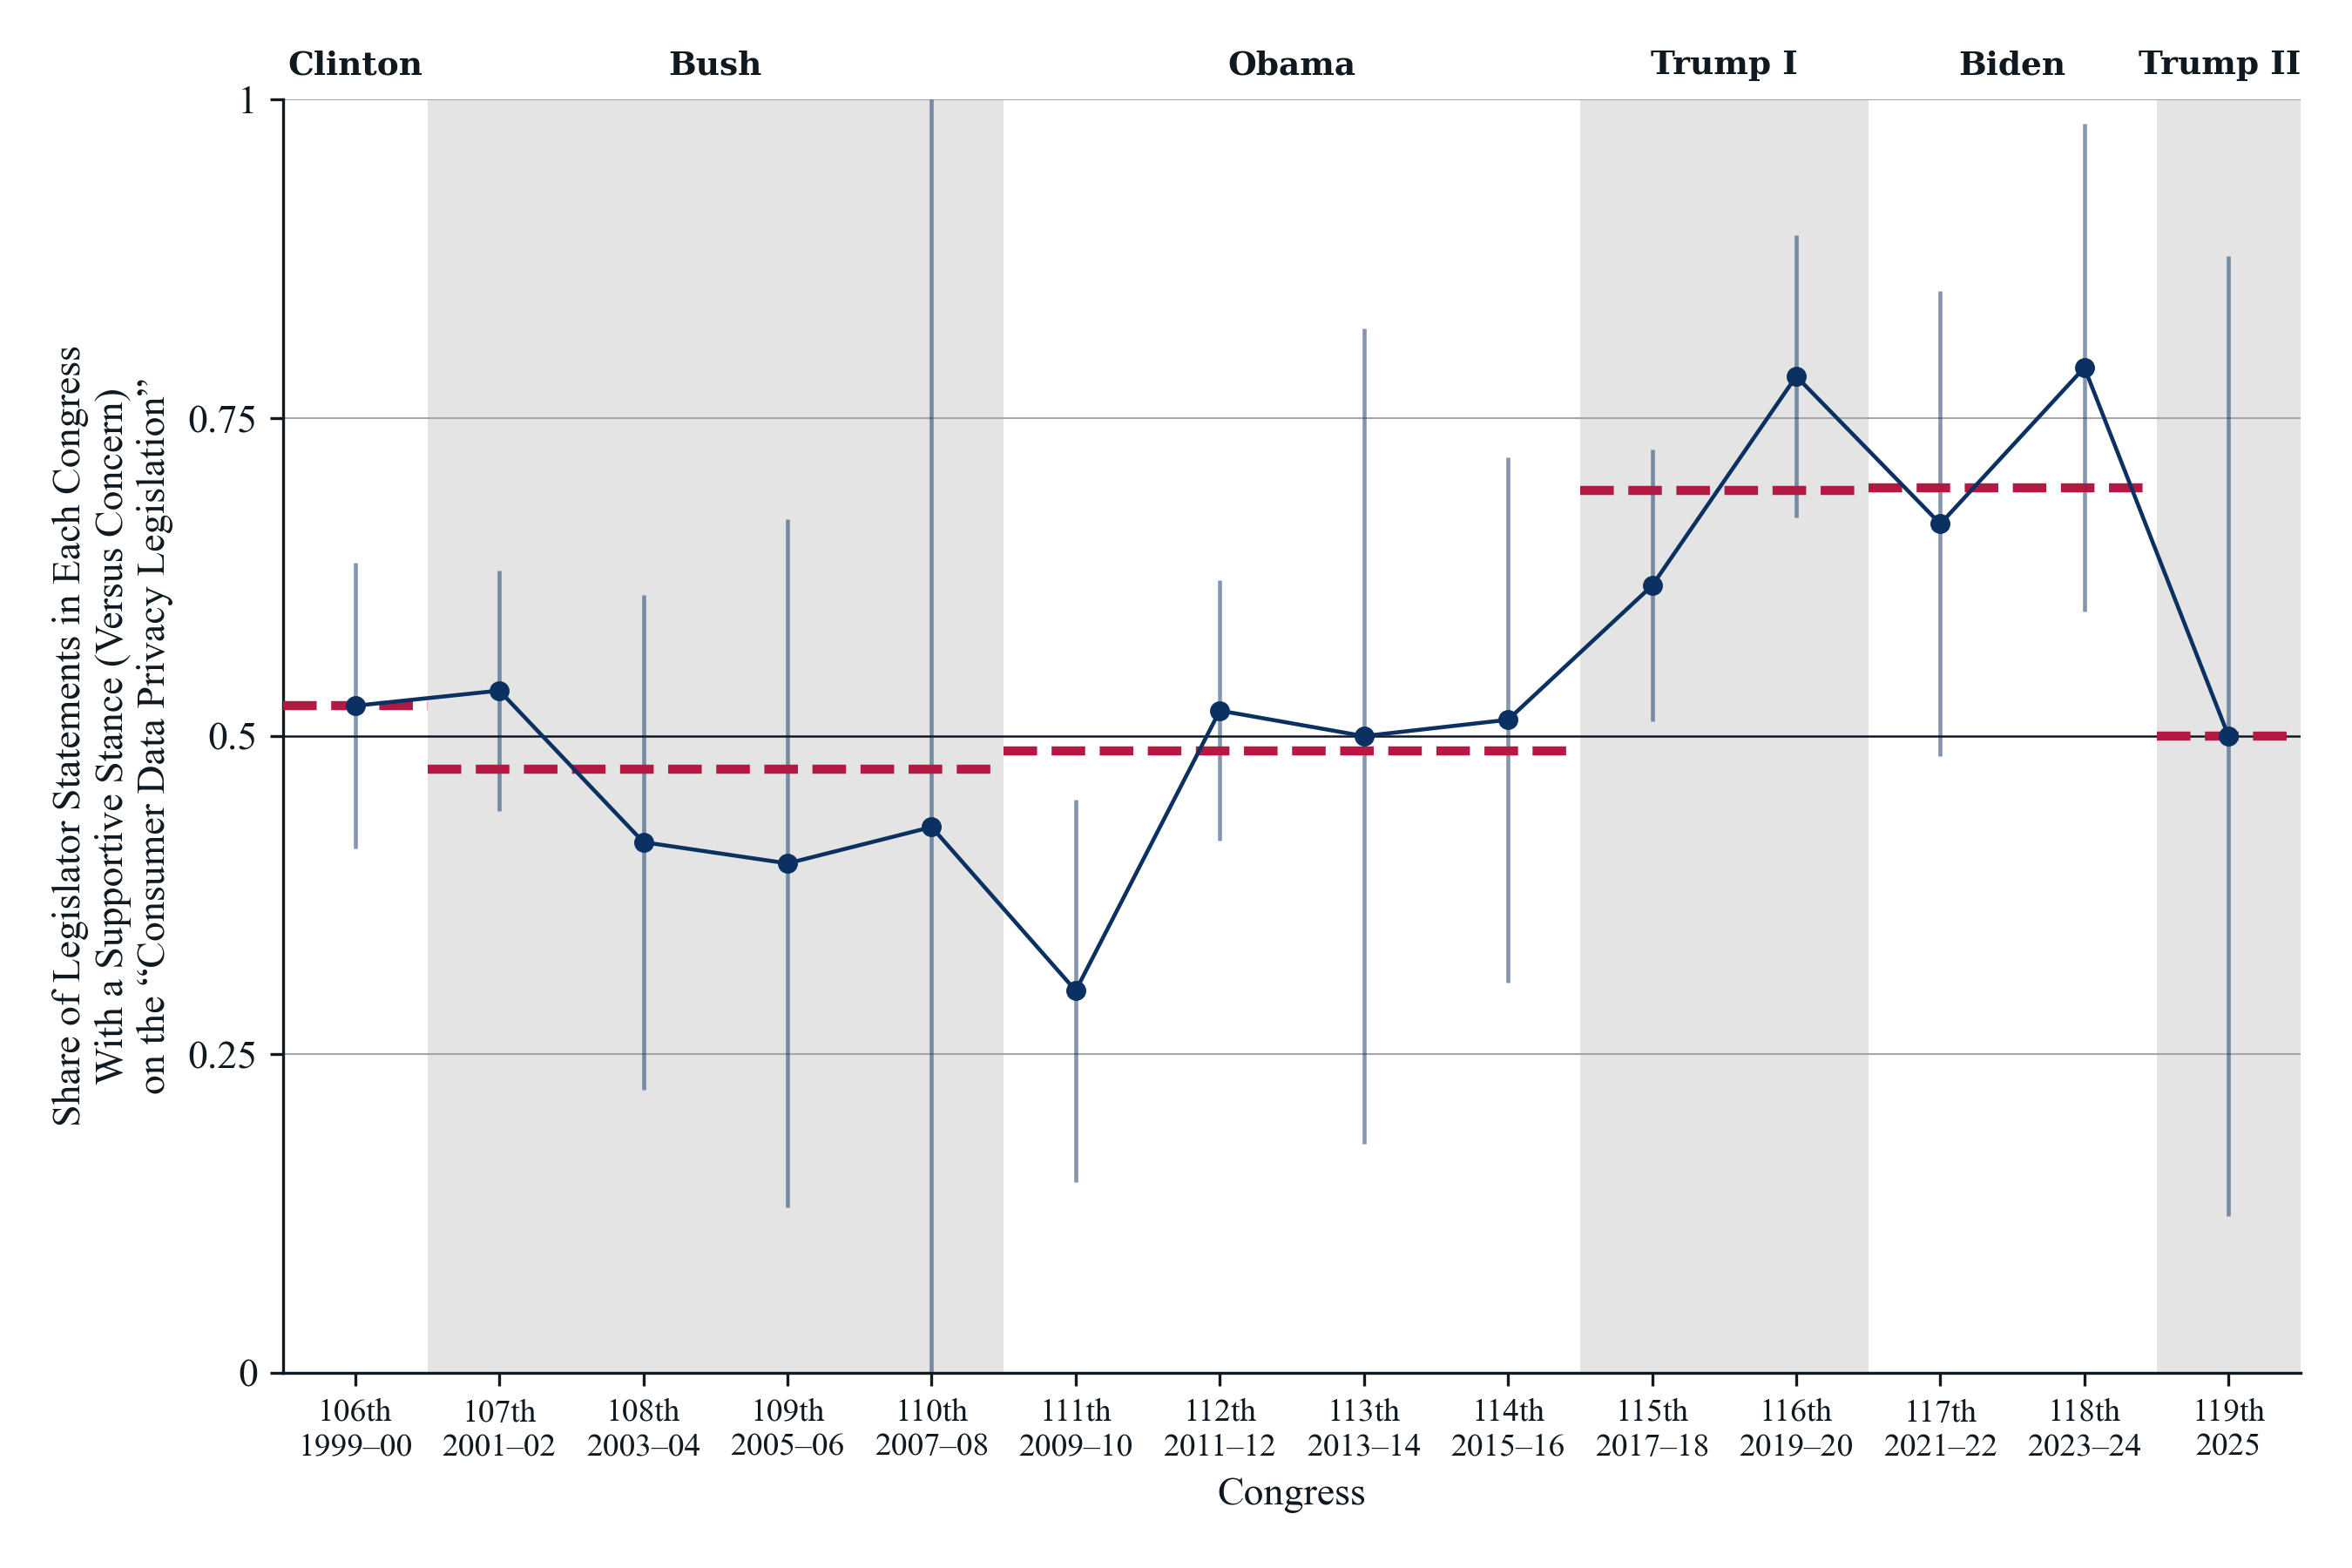

Saved PNG, SVG, and PDF: /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T2 - Topic Extraction and Stance Analysis/T2.4 - Running Example Selection/output/T2.4.2/fig_privacy_support_share_by_congress_panel_a


In [16]:
panel = "A"
figure_name = "fig_privacy_support_share_by_congress_panel_a"
figure_title = (
    "Figure 1. Share of Supportive Legislator Statements in Privacy and Digital Consumer Protection, "
    "by Congress"
)
panel_congress = congress_counts.loc[congress_counts["panel"].eq(panel)].set_index("congress")
panel_administration = administration_counts.loc[administration_counts["panel"].eq(panel)]

figure, axis = plt.subplots()
figure.subplots_adjust(
    left=0.12, right=1 - MARGIN_INCHES / FIGURE_WIDTH, top=0.9, bottom=0.2
)
axis.set_xlim(CONGRESS_MIN - 0.5, CONGRESS_MAX + 0.5)
axis.set_ylim(0, 1)

axis.vlines(
    panel_congress.index.to_numpy(), panel_congress["ci_lower"], panel_congress["ci_upper"],
    color=BLUE, alpha=0.5, linewidth=1.1, zorder=2,
)
axis.plot(
    panel_congress.index.to_numpy(), panel_congress["support_share"], color=BLUE, marker="o",
    markersize=4.5, linewidth=1.1, zorder=4,
    clip_on=False,  # draw whole markers at shares of exactly 0 or 1
)
for period in panel_administration.itertuples(index=False):
    first_congress, last_congress = TERM_CONGRESSES[period.administration]
    axis.hlines(
        period.support_share, first_congress - 0.5, last_congress + 0.5,
        color=RED, linewidth=2.5, linestyle="--", zorder=3,
    )
for position, (administration, first_year, last_year) in enumerate(ADMINISTRATION_WINDOWS):
    if position % 2 == 1:  # shade every second term so each boundary is visible
        first_congress, last_congress = TERM_CONGRESSES[administration]
        axis.axvspan(
            first_congress - 0.5, last_congress + 0.5, color=GREY, alpha=TERM_BAND_ALPHA,
            linewidth=0, zorder=0,
        )
axis.set_yticks([0, 0.25, EQUAL_SHARE, 0.75, 1], labels=["0", "0.25", "0.5", "0.75", "1"])
axis.set_ylabel(Y_TITLES[panel])
axis.set_xlabel("Congress")

# Two-line tick labels: the Congress number over its calendar years, in the short 2017–18 form
# so that fourteen labels fit the axis width; the last Congress shows only the sample's final year
congress_tick_labels = []
for congress in range(CONGRESS_MIN, CONGRESS_MAX + 1):
    first_year = YEAR_MIN + 2 * (congress - FIRST_CONGRESS)
    last_year = min(first_year + 1, YEAR_MAX)
    year_text = str(first_year) if last_year == first_year else f"{first_year}–{str(last_year)[-2:]}"
    congress_tick_labels.append(f"{congress}th\n{year_text}")
axis.set_xticks(range(CONGRESS_MIN, CONGRESS_MAX + 1), labels=congress_tick_labels)
axis.tick_params(axis="x", labelsize=9)
axis.spines[["top", "right"]].set_visible(False)
for tick, gridline in zip(axis.get_yticks(), axis.get_ygridlines()):
    if tick == EQUAL_SHARE:
        gridline.set_visible(False)
axis.axhline(EQUAL_SHARE, color=BLACK, linewidth=REFERENCE_LINE_WIDTH, zorder=2)

administration_labels = []
for administration, first_year, last_year in ADMINISTRATION_WINDOWS:
    first_congress, last_congress = TERM_CONGRESSES[administration]
    label_position = axis.get_xlim()[1] if last_congress == CONGRESS_MAX else (first_congress + last_congress) / 2
    label_alignment = "right" if last_congress == CONGRESS_MAX else "center"
    administration_labels.append(axis.text(
        label_position, 1.02, administration,
        transform=axis.get_xaxis_transform(), ha=label_alignment, va="baseline",
        fontsize=9, clip_on=False, **BOLD_TEXT,
    ))

# No legend inside the image: Step 18 draws both panels with the shared legend in one image.
# Set the outside margins: 0.5 cm from the Y-title, the term labels, and the X-title.
figure.canvas.draw()
renderer = figure.canvas.get_renderer()
margin_pixels = MARGIN_INCHES * figure.dpi
left_shift = (margin_pixels - axis.yaxis.label.get_window_extent(renderer).x0) / figure.bbox.width
label_top = max(label.get_window_extent(renderer).y1 for label in administration_labels)
top_shift = (figure.bbox.height - margin_pixels - label_top) / figure.bbox.height
label_bottom = axis.xaxis.label.get_window_extent(renderer).y0
bottom_shift = (margin_pixels - label_bottom) / figure.bbox.height
figure.subplots_adjust(
    left=figure.subplotpars.left + left_shift,
    top=figure.subplotpars.top + top_shift,
    bottom=figure.subplotpars.bottom + bottom_shift,
)

for extension in ["png", "svg", "pdf"]:
    figure.savefig(OUTPUT_FOLDER / f"{figure_name}.{extension}", dpi=EXPORT_DPI)
plt.close(figure)

display(Markdown(f"**{figure_title}**"))
display(Markdown(f"*Panel A. {PANEL_NAMES['A']}*"))
display(Image(filename=str(OUTPUT_FOLDER / f"{figure_name}.png"), width=900))
print(f"Saved PNG, SVG, and PDF: {OUTPUT_FOLDER / figure_name}")


## Step 17. Draw Panel B, the other four privacy topics pooled, by Congress

Repeat the Panel A drawing for the pooled records of the other four topics, with the same axes and bands, so the two images read as one figure. Display the panel heading and the image.


*Panel B. Other four privacy and digital consumer protection topics pooled*

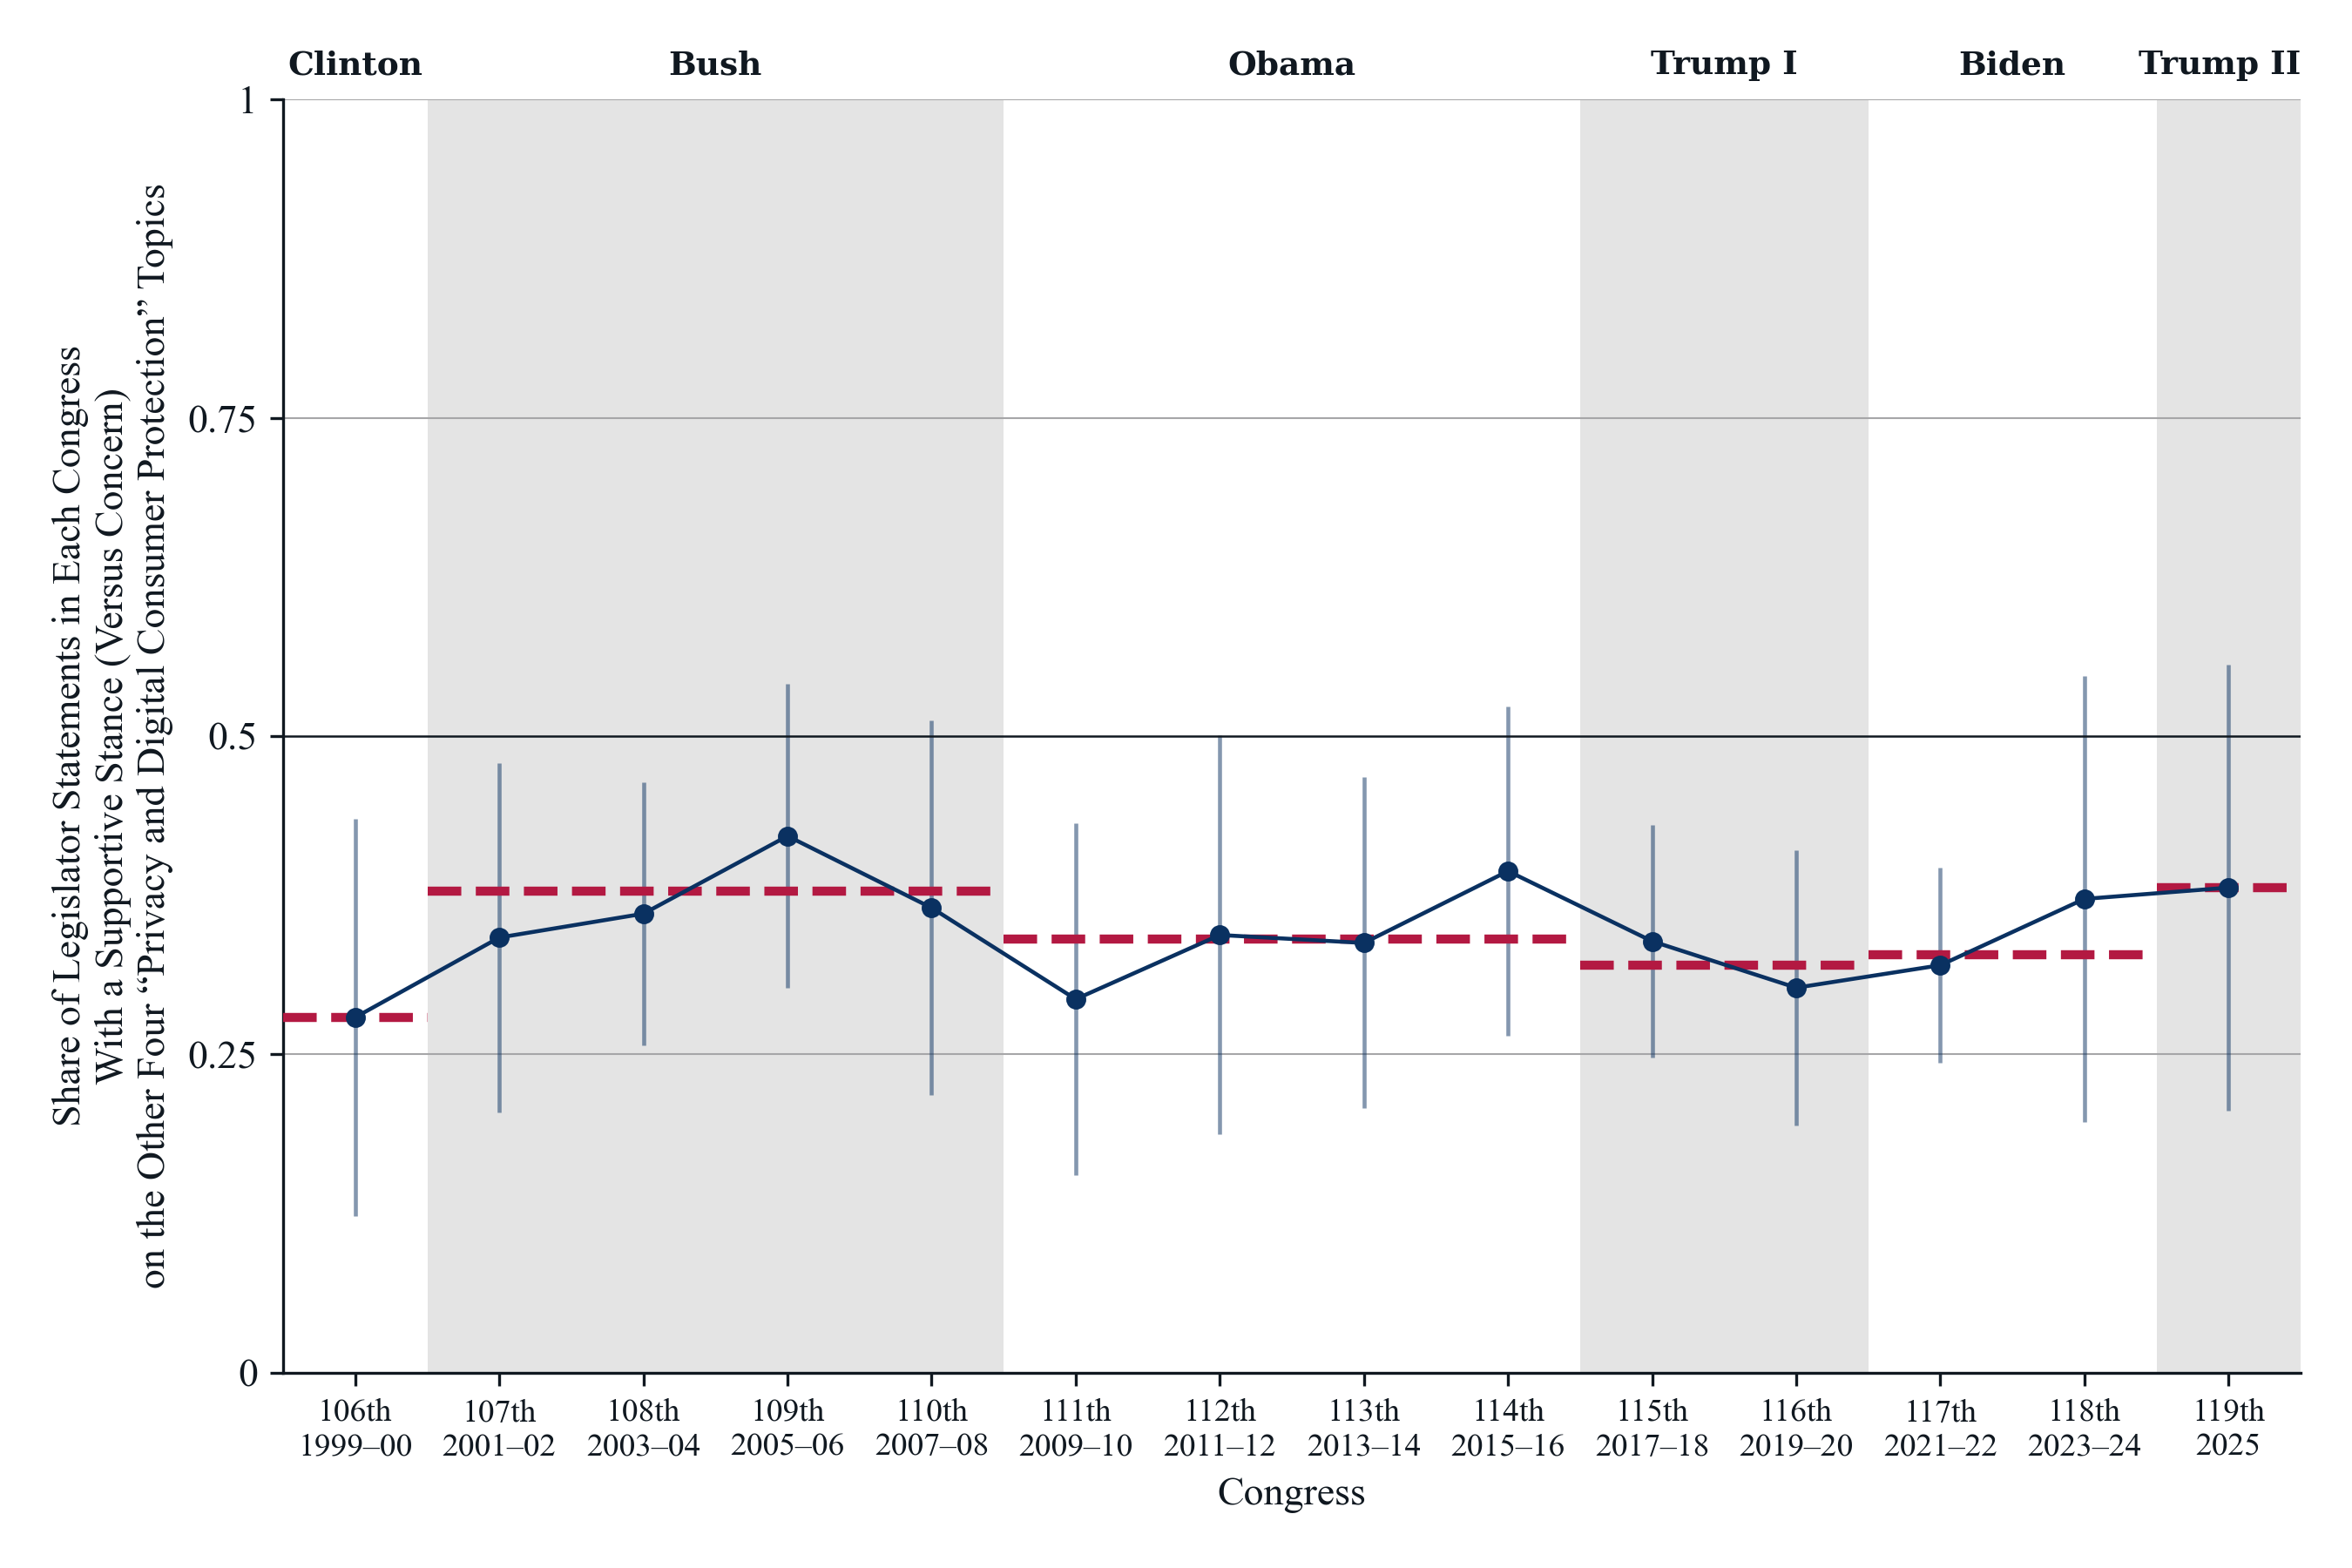

Saved PNG, SVG, and PDF: /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T2 - Topic Extraction and Stance Analysis/T2.4 - Running Example Selection/output/T2.4.2/fig_privacy_support_share_by_congress_panel_b


In [17]:
panel = "B"
figure_name = "fig_privacy_support_share_by_congress_panel_b"
panel_congress = congress_counts.loc[congress_counts["panel"].eq(panel)].set_index("congress")
panel_administration = administration_counts.loc[administration_counts["panel"].eq(panel)]

figure, axis = plt.subplots()
figure.subplots_adjust(
    left=0.12, right=1 - MARGIN_INCHES / FIGURE_WIDTH, top=0.9, bottom=0.2
)
axis.set_xlim(CONGRESS_MIN - 0.5, CONGRESS_MAX + 0.5)
axis.set_ylim(0, 1)

axis.vlines(
    panel_congress.index.to_numpy(), panel_congress["ci_lower"], panel_congress["ci_upper"],
    color=BLUE, alpha=0.5, linewidth=1.1, zorder=2,
)
axis.plot(
    panel_congress.index.to_numpy(), panel_congress["support_share"], color=BLUE, marker="o",
    markersize=4.5, linewidth=1.1, zorder=4,
    clip_on=False,  # draw whole markers at shares of exactly 0 or 1
)
for period in panel_administration.itertuples(index=False):
    first_congress, last_congress = TERM_CONGRESSES[period.administration]
    axis.hlines(
        period.support_share, first_congress - 0.5, last_congress + 0.5,
        color=RED, linewidth=2.5, linestyle="--", zorder=3,
    )
for position, (administration, first_year, last_year) in enumerate(ADMINISTRATION_WINDOWS):
    if position % 2 == 1:  # shade every second term so each boundary is visible
        first_congress, last_congress = TERM_CONGRESSES[administration]
        axis.axvspan(
            first_congress - 0.5, last_congress + 0.5, color=GREY, alpha=TERM_BAND_ALPHA,
            linewidth=0, zorder=0,
        )
axis.set_yticks([0, 0.25, EQUAL_SHARE, 0.75, 1], labels=["0", "0.25", "0.5", "0.75", "1"])
axis.set_ylabel(Y_TITLES[panel])
axis.set_xlabel("Congress")

# Two-line tick labels: the Congress number over its calendar years, in the short 2017–18 form
# so that fourteen labels fit the axis width; the last Congress shows only the sample's final year
congress_tick_labels = []
for congress in range(CONGRESS_MIN, CONGRESS_MAX + 1):
    first_year = YEAR_MIN + 2 * (congress - FIRST_CONGRESS)
    last_year = min(first_year + 1, YEAR_MAX)
    year_text = str(first_year) if last_year == first_year else f"{first_year}–{str(last_year)[-2:]}"
    congress_tick_labels.append(f"{congress}th\n{year_text}")
axis.set_xticks(range(CONGRESS_MIN, CONGRESS_MAX + 1), labels=congress_tick_labels)
axis.tick_params(axis="x", labelsize=9)
axis.spines[["top", "right"]].set_visible(False)
for tick, gridline in zip(axis.get_yticks(), axis.get_ygridlines()):
    if tick == EQUAL_SHARE:
        gridline.set_visible(False)
axis.axhline(EQUAL_SHARE, color=BLACK, linewidth=REFERENCE_LINE_WIDTH, zorder=2)

administration_labels = []
for administration, first_year, last_year in ADMINISTRATION_WINDOWS:
    first_congress, last_congress = TERM_CONGRESSES[administration]
    label_position = axis.get_xlim()[1] if last_congress == CONGRESS_MAX else (first_congress + last_congress) / 2
    label_alignment = "right" if last_congress == CONGRESS_MAX else "center"
    administration_labels.append(axis.text(
        label_position, 1.02, administration,
        transform=axis.get_xaxis_transform(), ha=label_alignment, va="baseline",
        fontsize=9, clip_on=False, **BOLD_TEXT,
    ))

# No legend inside the image: Step 18 draws both panels with the shared legend in one image.
# Set the outside margins: 0.5 cm from the Y-title, the term labels, and the X-title.
figure.canvas.draw()
renderer = figure.canvas.get_renderer()
margin_pixels = MARGIN_INCHES * figure.dpi
left_shift = (margin_pixels - axis.yaxis.label.get_window_extent(renderer).x0) / figure.bbox.width
label_top = max(label.get_window_extent(renderer).y1 for label in administration_labels)
top_shift = (figure.bbox.height - margin_pixels - label_top) / figure.bbox.height
label_bottom = axis.xaxis.label.get_window_extent(renderer).y0
bottom_shift = (margin_pixels - label_bottom) / figure.bbox.height
figure.subplots_adjust(
    left=figure.subplotpars.left + left_shift,
    top=figure.subplotpars.top + top_shift,
    bottom=figure.subplotpars.bottom + bottom_shift,
)

for extension in ["png", "svg", "pdf"]:
    figure.savefig(OUTPUT_FOLDER / f"{figure_name}.{extension}", dpi=EXPORT_DPI)
plt.close(figure)

display(Markdown(f"*Panel B. {PANEL_NAMES['B']}*"))
display(Image(filename=str(OUTPUT_FOLDER / f"{figure_name}.png"), width=900))
print(f"Saved PNG, SVG, and PDF: {OUTPUT_FOLDER / figure_name}")


## Step 18. Draw both panels with the shared legend in one image

For the document, draw Panel A and Panel B side by side on one canvas twice the standard width, each with the same drawing as Steps 16 and 17, and place the shared legend in one row across the bottom: the grey shading for presidential terms and the red dashed line for the term's pooled share. Keep the 0.5 cm outside margins and check that the Panel B Y-title clears Panel A. Display the combined image with the Notes and Source that cover both panels.


Gap between Panel A and the Panel B Y-title: 0.28 inches


*Panels A and B with the shared legend*

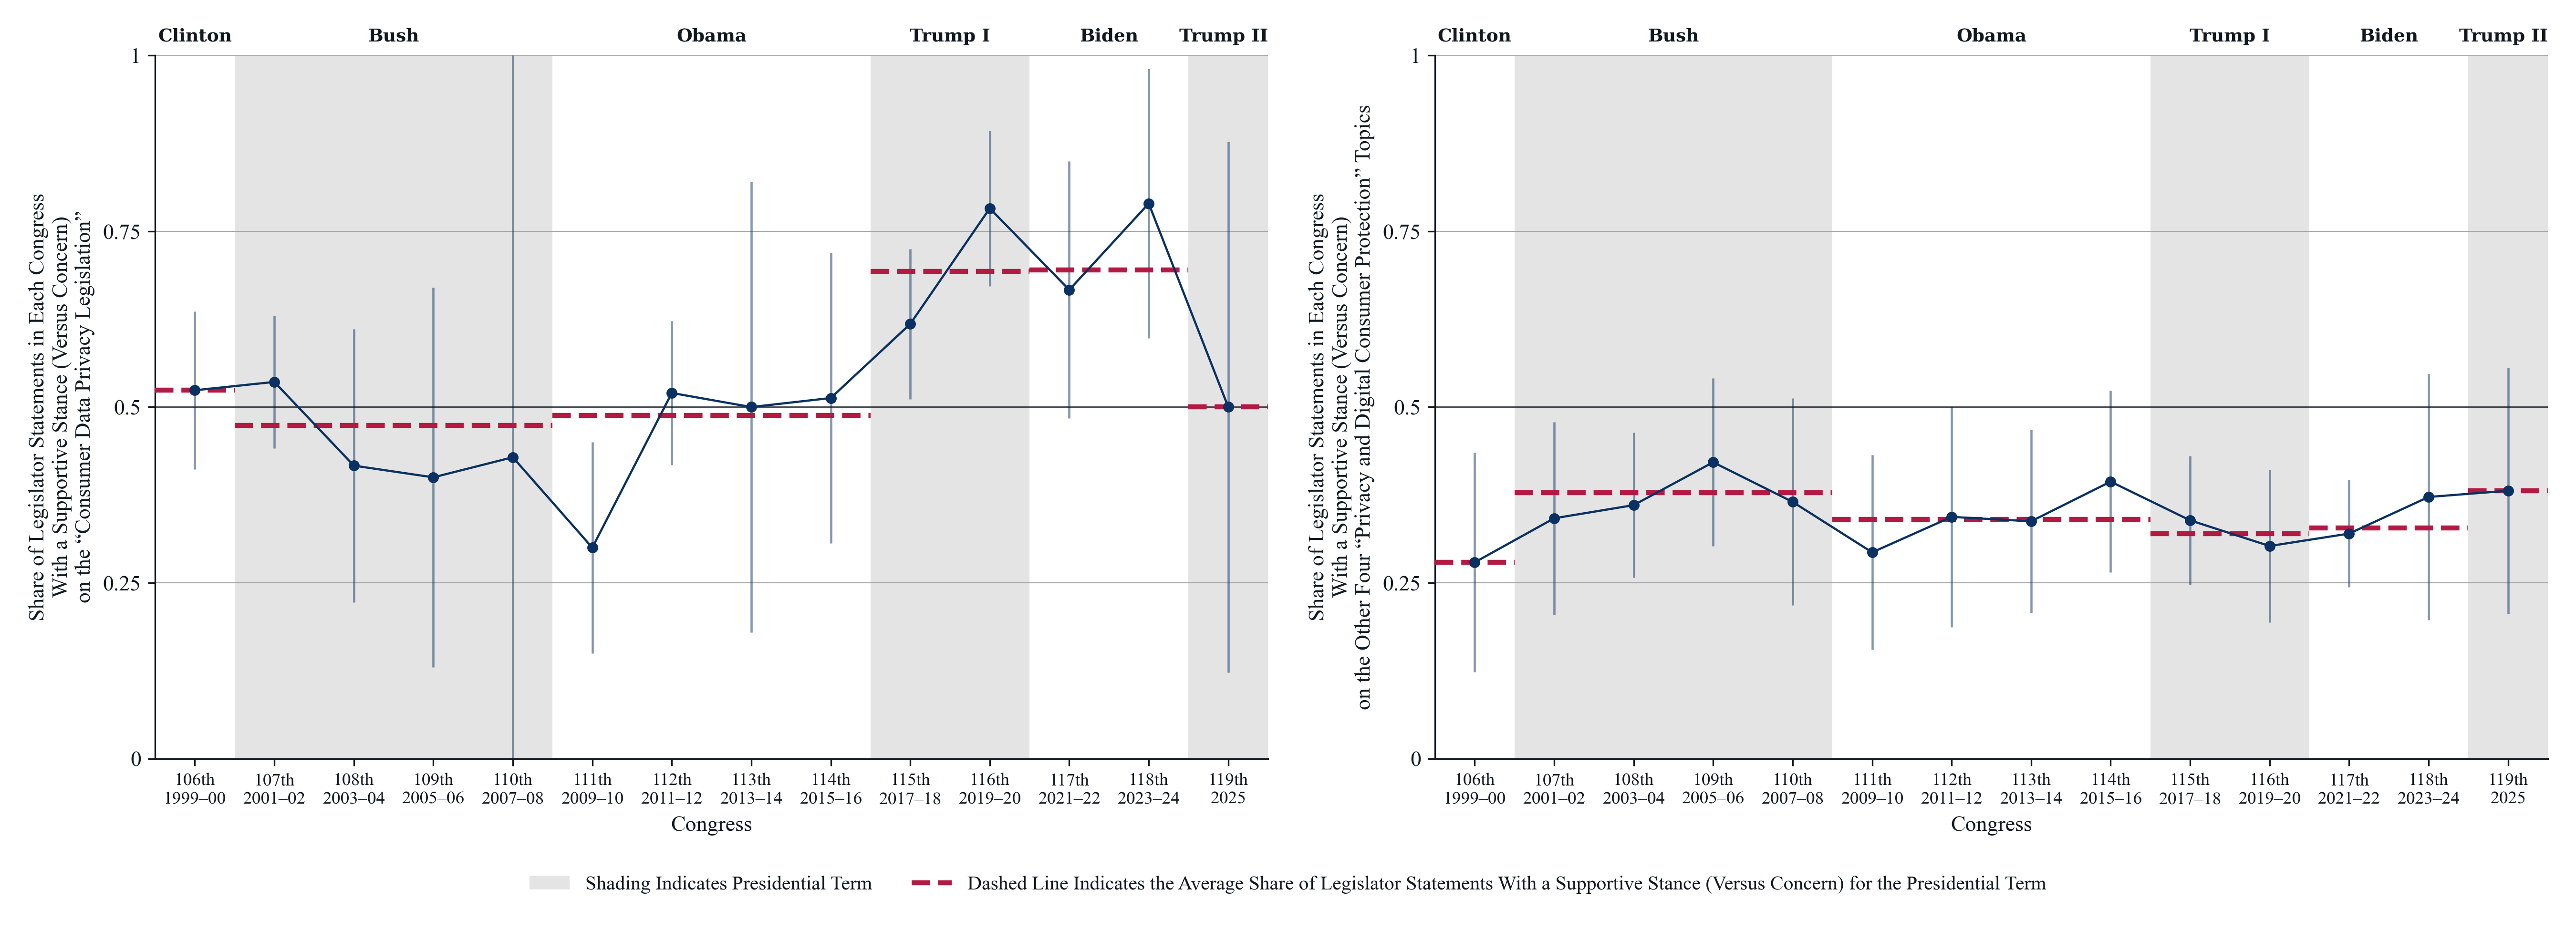

*Notes*: Sample: House Science and Senate Commerce hearings, 1999–2025. Panel A covers the topic consumer data privacy legislation: 119 hearings, 243 legislator speech turns, and 374 statements. Panel B pools the group's other 4 topics (Consumer privacy and anti-spam legislation; Digital identity verification and protection; Children's online privacy and safety legislation; Online advertising and consumer choice policies): 512 hearings, 904 legislator speech turns, and 1,280 statements. Each statement is one extracted legislator position on a topic; a speech turn may contain several. Each point pools all hearings held during one Congress, the two calendar years beginning in an odd year, shown under the Congress number on the horizontal axis: the 106th Congress is 1999–2000 and the 119th is 2025 alone. Each point is support statements ÷ (support + concern statements) across those hearings; the solid line at 0.5 marks equal numbers of support and concern statements. Vertical bars are 95 percent confidence intervals for the pooled share with standard errors clustered by hearing, so each hearing, not each statement, is the independent unit; every Congress has at least 3 hearings in Panel A and 18 in Panel B. Red dashed lines show the same share pooled over all statements in each presidential term, not the unweighted average of its Congress-level points. Alternating grey bands mark presidential terms as calendar-year blocks (Clinton 1999–2000, Bush 2001–2008, Obama 2009–2016, Trump I 2017–2020, Biden 2021–2024, Trump II 2025), which coincide with Congress boundaries. In the combined image, Panel A is on the left and Panel B on the right, and the legend applies to both.

*Source*: Saved legislator stance extraction and the approved manual topic grouping.

Saved PNG, SVG, and PDF: /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T2 - Topic Extraction and Stance Analysis/T2.4 - Running Example Selection/output/T2.4.2/fig_privacy_support_share_by_congress_both_panels


In [18]:
figure_name = "fig_privacy_support_share_by_congress_both_panels"
congress_tick_labels = []
for congress in range(CONGRESS_MIN, CONGRESS_MAX + 1):
    first_year = YEAR_MIN + 2 * (congress - FIRST_CONGRESS)
    last_year = min(first_year + 1, YEAR_MAX)
    year_text = str(first_year) if last_year == first_year else f"{first_year}–{str(last_year)[-2:]}"
    congress_tick_labels.append(f"{congress}th\n{year_text}")

figure, axes = plt.subplots(1, 2, figsize=(COMBINED_FIGURE_WIDTH, COMBINED_FIGURE_HEIGHT))
figure.subplots_adjust(
    left=0.07, right=1 - MARGIN_INCHES / COMBINED_FIGURE_WIDTH, top=0.9, bottom=0.2, wspace=0.15
)
administration_labels = []
for axis, panel in zip(axes, PANEL_NAMES):
    panel_congress = congress_counts.loc[congress_counts["panel"].eq(panel)].set_index("congress")
    panel_administration = administration_counts.loc[administration_counts["panel"].eq(panel)]
    axis.set_xlim(CONGRESS_MIN - 0.5, CONGRESS_MAX + 0.5)
    axis.set_ylim(0, 1)
    axis.vlines(
        panel_congress.index.to_numpy(), panel_congress["ci_lower"], panel_congress["ci_upper"],
        color=BLUE, alpha=0.5, linewidth=1.1, zorder=2,
    )
    axis.plot(
        panel_congress.index.to_numpy(), panel_congress["support_share"], color=BLUE, marker="o",
        markersize=4.5, linewidth=1.1, zorder=4,
        clip_on=False,  # draw whole markers at shares of exactly 0 or 1
    )
    for period in panel_administration.itertuples(index=False):
        first_congress, last_congress = TERM_CONGRESSES[period.administration]
        axis.hlines(
            period.support_share, first_congress - 0.5, last_congress + 0.5,
            color=RED, linewidth=2.5, linestyle="--", zorder=3,
        )
    for position, (administration, first_year, last_year) in enumerate(ADMINISTRATION_WINDOWS):
        if position % 2 == 1:  # shade every second term so each boundary is visible
            first_congress, last_congress = TERM_CONGRESSES[administration]
            axis.axvspan(
                first_congress - 0.5, last_congress + 0.5, color=GREY, alpha=TERM_BAND_ALPHA,
                linewidth=0, zorder=0,
            )
    axis.set_yticks([0, 0.25, EQUAL_SHARE, 0.75, 1], labels=["0", "0.25", "0.5", "0.75", "1"])
    axis.set_ylabel(Y_TITLES[panel])
    axis.set_xlabel("Congress")
    axis.set_xticks(range(CONGRESS_MIN, CONGRESS_MAX + 1), labels=congress_tick_labels)
    axis.tick_params(axis="x", labelsize=9)
    axis.spines[["top", "right"]].set_visible(False)
    for tick, gridline in zip(axis.get_yticks(), axis.get_ygridlines()):
        if tick == EQUAL_SHARE:
            gridline.set_visible(False)
    axis.axhline(EQUAL_SHARE, color=BLACK, linewidth=REFERENCE_LINE_WIDTH, zorder=2)
    for administration, first_year, last_year in ADMINISTRATION_WINDOWS:
        first_congress, last_congress = TERM_CONGRESSES[administration]
        label_position = axis.get_xlim()[1] if last_congress == CONGRESS_MAX else (first_congress + last_congress) / 2
        label_alignment = "right" if last_congress == CONGRESS_MAX else "center"
        administration_labels.append(axis.text(
            label_position, 1.02, administration,
            transform=axis.get_xaxis_transform(), ha=label_alignment, va="baseline",
            fontsize=9, clip_on=False, **BOLD_TEXT,
        ))

legend_handles = [
    Patch(facecolor=GREY, alpha=TERM_BAND_ALPHA, linewidth=0),
    Line2D([], [], color=RED, linewidth=2.5, linestyle="--"),
]
legend_labels = [
    "Shading Indicates Presidential Term",
    "Dashed Line Indicates the Average Share of Legislator Statements "
    "With a Supportive Stance (Versus Concern) for the Presidential Term",
]
legend = figure.legend(
    legend_handles, legend_labels, loc="lower center",
    bbox_to_anchor=(0.5, MARGIN_INCHES / COMBINED_FIGURE_HEIGHT), bbox_transform=figure.transFigure,
    ncol=2, frameon=False, fontsize=LEGEND_FONT_SIZE, borderaxespad=0,
)

# Set the outside margins: 0.5 cm from the Panel A Y-title, the term labels, and the legend,
# with the X-titles 0.5 cm above the legend.
figure.canvas.draw()
renderer = figure.canvas.get_renderer()
margin_pixels = MARGIN_INCHES * figure.dpi
left_shift = (margin_pixels - axes[0].yaxis.label.get_window_extent(renderer).x0) / figure.bbox.width
label_top = max(label.get_window_extent(renderer).y1 for label in administration_labels)
top_shift = (figure.bbox.height - margin_pixels - label_top) / figure.bbox.height
legend_top = legend.get_window_extent(renderer).y1
label_bottom = min(axis.xaxis.label.get_window_extent(renderer).y0 for axis in axes)
bottom_shift = (legend_top + margin_pixels - label_bottom) / figure.bbox.height
figure.subplots_adjust(
    left=figure.subplotpars.left + left_shift,
    top=figure.subplotpars.top + top_shift,
    bottom=figure.subplotpars.bottom + bottom_shift,
)
figure.canvas.draw()
panel_gap = axes[1].yaxis.label.get_window_extent(renderer).x0 - axes[0].get_window_extent(renderer).x1
assert panel_gap >= margin_pixels, panel_gap / figure.dpi
print(f"Gap between Panel A and the Panel B Y-title: {panel_gap / figure.dpi:.2f} inches")

for extension in ["png", "svg", "pdf"]:
    figure.savefig(OUTPUT_FOLDER / f"{figure_name}.{extension}", dpi=EXPORT_DPI)
plt.close(figure)

fewest_hearings = congress_counts.groupby("panel")["n_hearings"].min()
term_list = ", ".join(
    f"{administration} {first_year}" if first_year == last_year else f"{administration} {first_year}–{last_year}"
    for administration, first_year, last_year in ADMINISTRATION_WINDOWS
)
figure_notes = (
    f"Sample: {sample_description} Each statement is one extracted legislator position on a topic; "
    "a speech turn may contain several. Each point pools all hearings held during one Congress, the two "
    "calendar years beginning in an odd year, shown under the Congress number on the horizontal axis: "
    f"the {CONGRESS_MIN}th Congress is {YEAR_MIN}–{YEAR_MIN + 1} and the {CONGRESS_MAX}th is {YEAR_MAX} alone. "
    "Each point is support statements ÷ (support + concern statements) across those hearings; the solid "
    "line at 0.5 marks equal numbers of support and concern statements. Vertical bars are 95 percent "
    "confidence intervals for the pooled share with standard errors clustered by hearing, so each "
    "hearing, not each statement, is the independent unit; every Congress has at least "
    f"{fewest_hearings['A']} hearings in Panel A and {fewest_hearings['B']} in Panel B. Red dashed lines "
    "show the same share pooled over all statements in each presidential term, not the unweighted "
    "average of its Congress-level points. Alternating grey bands mark presidential terms as "
    f"calendar-year blocks ({term_list}), which coincide with Congress boundaries. In the combined image, "
    "Panel A is on the left and Panel B on the right, and the legend applies to both."
)
display(Markdown("*Panels A and B with the shared legend*"))
display(Image(filename=str(OUTPUT_FOLDER / f"{figure_name}.png"), width=900))
display(Markdown(f"*Notes*: {figure_notes}\n\n*Source*: {figure_source}"))
print(f"Saved PNG, SVG, and PDF: {OUTPUT_FOLDER / figure_name}")
